<a href="https://colab.research.google.com/github/piihutanoch/pet-breed-classifier/blob/main/notebooks/02_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json, sys, time
import torch
import pandas as pd

Mounted at /content/drive


In [2]:
project_dir= Path("/content/drive/MyDrive/pet-breed-classifier")
artifacts_dir= project_dir/"artifacts_v2"    # v2 artifacts (v1 is kept in artifacts/)
src_dir= project_dir/"src"            # reusable .py files live here
data_dir= Path("/content/data")

artifacts_dir.mkdir(parents=True, exist_ok=True)
src_dir.mkdir(parents=True, exist_ok= True)
data_dir.mkdir(parents=True, exist_ok= True)

In [3]:
seed= 42
torch.manual_seed(seed)

# Select GPU when CUDA is available
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


In [4]:
# Oxford-IIIT Pet
!wget -q --show-progress https://s3.amazonaws.com/fast-ai-imageclas/oxford-iiit-pet.tgz -O /content/pets.tgz
!tar -xzf /content/pets.tgz -C /content/data
!ls /content/data/oxford-iiit-pet

# Stanford Dogs from Kaggle
import kagglehub
kaggle_path= Path(kagglehub.dataset_download("jessicali9530/stanford-dogs-dataset"))

# Find the folder holding the 120 breed folders and link it to /content/data/Images
breeds_parent= next(kaggle_path.rglob("n02085620-Chihuahua")).parent
!rm -rf /content/data/Images
!ln -s "{breeds_parent}" /content/data/Images
!ls /content/data/Images | wc -l    # 120 breed folders

/content/pets.tgz   100%[===================>] 774.10M  47.7MB/s    in 17s     
annotations  images
Using Colab cache for faster access to the 'stanford-dogs-dataset' dataset.
120


### Downloading the Datasets

The Oxford-IIIT Pet dataset is downloaded and extracted to the local Colab disk, as in v1.

Stanford Dogs is downloaded from Kaggle using `kagglehub`. Since Kaggle may store it in a different location, the folder containing the 120 breed folders is located and linked to `/content/data/Images`. This keeps the image paths consistent with the ones saved in `roots.json`.

The Indie photos are read directly from Google Drive (`indie_raw/`), so they do not need to be downloaded.

In [5]:
# Load the dataset manifest created in 01b (one row per photo, with its split)
manifest= pd.read_csv(artifacts_dir/"manifest.csv")

# Location of each image source (Oxford / Stanford / Indie)
with open(artifacts_dir/"roots.json") as f:
    ROOTS= json.load(f)

# Load the numerical index-to-breed mapping
with open(artifacts_dir/"classes.json") as f:
    idx_to_class= json.load(f)

NUM_CLASSES= len(idx_to_class)    # 137

print(manifest["split"].value_counts().to_dict())   # train 17648, val 3784, test 3784
print("classes:", NUM_CLASSES)
print("class 0:", idx_to_class["0"])                 # JSON keys are strings

{'train': 17648, 'test': 3784, 'val': 3784}
classes: 137
class 0: Abyssinian


### Loading Saved Dataset Information

The v2 dataset is loaded from the files created in `01b_eda_build_dataset`.

The `manifest.csv` file replaces v1's `splits.json`. It stores one row per image:
- `source`: Where the image comes from (`oxford`, `stanford` or `indie`).
- `path`: The image path relative to its source folder.
- `breed`, `species`, `label`: The breed name, cat/dog and numerical class index.
- `split`: Whether the image belongs to the training (17,648), validation (3,784) or test (3,784) set.

The `roots.json` file stores the folder for each source, so image paths can be rebuilt in every new Colab session.

The `classes.json` file maps numerical class indices (0–136) to their corresponding breed names. `NUM_CLASSES` is taken from this mapping instead of hard-coding 37.

In [6]:
# Make the project directory available for imports
import importlib
sys.path.append(str(project_dir))

# Import and reload the custom data modules
import src.data, src.data_v2
importlib.reload(src.data)
importlib.reload(src.data_v2)
from src.data import get_eval_transform
from src.data_v2 import get_loaders_v2

# Create training, validation and test DataLoaders from the manifest
train_loader, val_loader, test_loader= get_loaders_v2(
    manifest, ROOTS, batch_size=32
)

# Baseline uses no augmentation: training images get the same preprocessing as validation
train_loader.dataset.transform= get_eval_transform()

print("train:", len(train_loader.dataset), "val:", len(val_loader.dataset), "test:", len(test_loader.dataset))

train: 17648 val: 3784 test: 3784


In [7]:
# Retrieve a batch to verify preprocessing
images, labels= next(iter(train_loader))

print("Batch shape:", images.shape)
print("Min:", round(images.min().item(), 2))
print("Max:", round(images.max().item(), 2))
print("Mean:", round(images.mean().item(), 2))

# Inspect the official EfficientNet-B0 preprocessing
from torchvision.models import EfficientNet_B0_Weights

print(EfficientNet_B0_Weights.DEFAULT.transforms())

Batch shape: torch.Size([32, 3, 224, 224])
Min: -2.12
Max: 2.64
Mean: -0.01
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)


### Verifying the Data Loading Pipeline

The data modules are imported and reloaded to ensure their latest versions are used. `src/data.py` provides the preprocessing (`get_eval_transform`), while `src/data_v2.py` reads the images listed in `manifest.csv`.

`get_loaders_v2()` creates the training, validation and test DataLoaders. The test loader is created but not used until Day 4.

`src/data.py` now contains the Day 3 training transform with augmentation. Since this is a baseline, the training dataset's transform is replaced with `get_eval_transform()`, so training images are only resized, centre-cropped and normalised, as in v1.

A batch is retrieved to verify its dimensions and normalised pixel value range. The preprocessing configuration is also compared with the official EfficientNet-B0 transformations to check compatibility with the pretrained model.

In [8]:
# Import and reload the custom model module
import src.model
importlib.reload(src.model)
from src.model import build_model

# Create EfficientNet-B0 with frozen pretrained layers
model= build_model("efficientnet_b0", num_classes=NUM_CLASSES, freeze=True)

# Move the model to the selected device (GPU/CPU)
model= model.to(device)

# Inspect the modified classification head
print(model.classifier)

# Count all model parameters, including frozen ones
total= sum(p.numel() for p in model.parameters())

# Count only parameters that will be updated during training
trainable= sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"total params: {total:,}")
print(f"trainable params: {trainable:,}") #(1280*137)+137 = 175,497

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=137, bias=True)
)
total params: 4,183,045
trainable params: 175,497


### Building the Model Architecture

EfficientNet-B0 is loaded with ImageNet-pretrained weights using transfer learning, using the `build_model()` function from `src/model.py`. Its pretrained convolutional layers act as a feature extractor, identifying useful visual patterns such as edges, textures and shapes.

When `freeze=True`, the pretrained weights are frozen using `requires_grad=False`, preventing them from being updated during training.

The original classification head, designed for 1,000 ImageNet classes, is replaced with a new Linear layer that maps the 1,280 input features to 137 breed classes.

Parameter inspection verifies the effect of freezing. Only the new classification layer is trainable: (1,280 × 137) + 137 = 175,497 parameters, compared with 47,397 for 37 classes in v1. The rest of the network keeps its pretrained weights.

In [9]:
def train_one_epoch(model, loader, loss_fn, optimizer, device):
    model.train()  # Enable training behaviour (e.g. dropout)
    total_loss, correct, count = 0.0, 0, 0

    for images, labels in loader:
        # Move the batch to the same device as the model
        images= images.to(device)
        labels= labels.to(device)

        # Forward pass: generate logits for all 137 classes
        outputs= model(images)
        loss= loss_fn(outputs, labels)

        # Backpropagation and weight update
        optimizer.zero_grad()  # Clear gradients from the previous batch
        loss.backward()        # Calculate gradients for trainable parameters
        optimizer.step()       # Update trainable weights

        # Accumulate loss and correct predictions across batches
        batch_size= images.size(0)
        total_loss+= loss.item() * batch_size  # Convert batch mean loss to total
        preds= outputs.argmax(dim=1)           # Select the highest-scoring class
        correct+= (preds== labels).sum().item()
        count+= batch_size

    return total_loss/count, correct/count

In [10]:
def evaluate(model, loader, loss_fn, device):
    model.eval()  # Disable training-specific behaviour (e.g. dropout)
    total_loss, correct, count = 0.0, 0, 0

    # Disable gradient tracking since no weight updates are needed
    with torch.no_grad():
        for images, labels in loader:
            images= images.to(device)
            labels= labels.to(device)

            # Generate predictions and calculate loss
            outputs= model(images)
            loss= loss_fn(outputs, labels)

            # Accumulate loss and accuracy across batches
            batch_size= images.size(0)
            total_loss+= loss.item()*batch_size
            preds= outputs.argmax(dim=1)
            correct+= (preds==labels).sum().item()
            count+= batch_size

    return total_loss / count, correct / count

In [11]:
import torch.nn as nn

loss_fn= nn.CrossEntropyLoss()

# Record the model's initial validation performance before training
val_loss0, val_acc0= evaluate(model, val_loader, loss_fn, device)

print(f"Before training -> val loss: {val_loss0:.2f}, val acc: {val_acc0:.3f}")   # expected ~ln(137) = 4.92 and ~1/137 = 0.007

Before training -> val loss: 4.93, val acc: 0.004


### Training and Evaluation Functions

The training function processes the dataset in batches. For each batch, the model generates predictions through forward propagation, and CrossEntropyLoss measures the prediction error. Backpropagation calculates gradients, which the optimizer uses to update the trainable parameters.

Loss and accuracy are accumulated across batches to calculate the overall training metrics for an epoch.

The evaluation function measures performance on the validation set without updating model weights. Evaluation mode disables training-specific behaviour such as dropout, while torch.no_grad() prevents unnecessary gradient calculations, reducing memory usage and computation.

An initial evaluation is performed before training to establish a baseline for comparison with subsequent results. With 137 classes, random guessing should give a loss of about ln(137) ≈ 4.92 and an accuracy of about 1/137 ≈ 0.7%.

In [12]:
optimizer= torch.optim.Adam(
    model.classifier.parameters(),  # Update only the trainable classifier parameters
    lr=1e-3
)

num_epochs= 5

# Store metrics from each epoch for later analysis and plotting
history= {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": [],
    "epoch_time": []
}

best_val_acc= 0.0
ckpt_path= artifacts_dir/"baseline_b0.pt"

for epoch in range(1, num_epochs+1):
    start= time.time()

    # Train on the training set, then evaluate on the validation set
    train_loss, train_acc= train_one_epoch(
        model, train_loader, loss_fn, optimizer, device
    )
    val_loss, val_acc= evaluate(
        model, val_loader, loss_fn, device
    )

    epoch_time= time.time()-start

    # Record metrics for this epoch
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["epoch_time"].append(epoch_time)

    # Display training progress
    print(f"Epoch {epoch}/{num_epochs} | "
          f"train loss {train_loss:.3f} acc {train_acc:.3f} | "
          f"val loss {val_loss:.3f} acc {val_acc:.3f} | {epoch_time:.0f}s")

    # Save the model whenever validation accuracy improves
    if val_acc > best_val_acc:
        best_val_acc= val_acc
        torch.save(model.state_dict(), ckpt_path)
        print("new best, checkpoint saved")

print("\nBest val accuracy:", round(best_val_acc, 4))

# Save training history as JSON for later analysis
with open(artifacts_dir/"baseline_history.json", "w") as f:
    json.dump(history, f)

Epoch 1/5 | train loss 2.323 acc 0.513 | val loss 1.248 acc 0.708 | 155s
new best, checkpoint saved
Epoch 2/5 | train loss 1.162 acc 0.719 | val loss 1.024 acc 0.726 | 112s
new best, checkpoint saved
Epoch 3/5 | train loss 0.924 acc 0.763 | val loss 0.936 acc 0.743 | 110s
new best, checkpoint saved
Epoch 4/5 | train loss 0.786 acc 0.794 | val loss 0.900 acc 0.744 | 111s
new best, checkpoint saved
Epoch 5/5 | train loss 0.690 acc 0.816 | val loss 0.861 acc 0.755 | 112s
new best, checkpoint saved

Best val accuracy: 0.755


### Baseline Model Training

The EfficientNet-B0 model is trained for five epochs using the Adam optimizer with a learning rate of 0.001. Only the classifier parameters are updated, while the pretrained feature extractor remains frozen.

After each epoch, the model is evaluated on the validation set. Training and validation loss, accuracy, and epoch duration are recorded to track performance.

A checkpoint containing the model parameters is saved whenever validation accuracy improves, ensuring that the best-performing model is retained. The training history is also saved as a JSON file for subsequent analysis and visualisation.

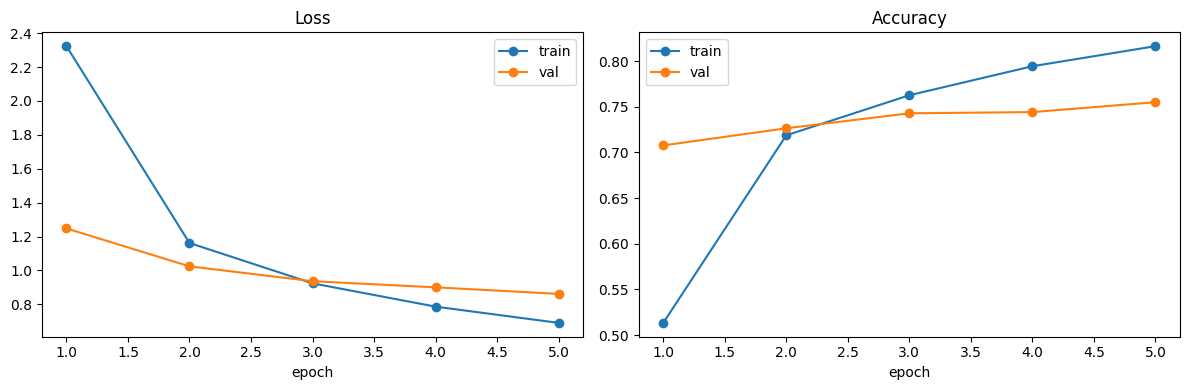

In [13]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(epochs, history["train_loss"], marker="o", label="train")
ax1.plot(epochs, history["val_loss"], marker="o", label="val")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()

ax2.plot(epochs, history["train_acc"], marker="o", label="train")
ax2.plot(epochs, history["val_acc"], marker="o", label="val")
ax2.set_title("Accuracy"); ax2.set_xlabel("epoch"); ax2.legend()

plt.tight_layout()
plt.savefig(artifacts_dir/"baseline_curves.png", dpi=120)   # dpi is dots per inch
plt.show()

### Baseline Training Results

The training loss decreased from approximately 2.33 to 0.69, while training accuracy improved from 51% to 82%. The low first-epoch training accuracy is expected: with 137 classes and 17,648 training images, the new classification layer starts from random predictions, and the training metrics are averaged while it is still learning.

Validation accuracy increased steadily from approximately 71% to 75.5%, and validation loss decreased from 1.25 to 0.86 across all five epochs. Unlike v1, where validation accuracy plateaued after epoch 2, both validation metrics were still improving at epoch 5. This suggests the frozen model had not yet reached its limit, rather than overfitting.

The model achieved its highest validation accuracy of approximately 75.5% at epoch 5. This is lower than v1's 88.41% because the task is harder: 137 classes instead of 37, including many visually similar dog breeds from Stanford Dogs that frozen ImageNet features cannot fully separate.

These results provide the v2 baseline for comparison with fine-tuning on Day 3.

In [14]:
# Recreate the same model architecture before loading its saved parameters
best_model= build_model(
    "efficientnet_b0", num_classes=NUM_CLASSES, freeze=True
).to(device)

# Load the best checkpoint into the recreated model
best_model.load_state_dict(
    torch.load(ckpt_path, map_location=device)
)

# Evaluate the reloaded model; only validation accuracy is needed
_, reloaded_acc = evaluate(best_model, val_loader, loss_fn, device)

# Compare accuracy before and after checkpoint reloading
print(
    "best during training:", round(best_val_acc, 4),
    "reloaded:", round(reloaded_acc, 4)
)

# Verify that the reloaded model reproduces the original performance
assert abs(reloaded_acc - best_val_acc) < 0.002

best during training: 0.755 reloaded: 0.755


### Checkpoint Verification

The best-performing model checkpoint is reloaded into a newly initialised EfficientNet-B0 architecture. Its validation accuracy is compared with the best validation accuracy recorded during training.

An assertion checks that the difference between the two values is within a small tolerance. This verifies that the saved model parameters can be restored correctly and reproduce the expected performance.